**Name** : **Nagawade Chirag Somnath**
**PRN** : **202502110009**


# Practical No. 02: Text Classification using Embedding Layer and LSTM
**Aim:** Build a text classification model using an **Embedding layer** and an **LSTM** network, and evaluate it using appropriate classification metrics.

**Task:** Binary sentiment classification (positive / negative) of movie reviews  
**Dataset:** IMDB Movie Reviews (50,000 reviews: 25,000 train, 25,000 test), built into Keras  


## 1. Import Libraries

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score)

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.20.0
GPU available: True


## 2. Load & Explore the Dataset
Reviews are already converted into sequences of integer word indices. We keep only the **10,000 most frequent words** (`VOCAB_SIZE`); rarer words are replaced by an out-of-vocabulary token.

In [2]:
VOCAB_SIZE = 10000     # size of vocabulary
MAX_LEN = 200          # max review length (words)

(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)
print("Training reviews:", len(x_train), "| Test reviews:", len(x_test))
print("Label distribution (train):", dict(zip(*np.unique(y_train, return_counts=True))))
print("Label distribution (test) :", dict(zip(*np.unique(y_test, return_counts=True))))

lengths = [len(s) for s in x_train]
print(f"Review length -> min {min(lengths)}, mean {np.mean(lengths):.0f}, median {int(np.median(lengths))}, max {max(lengths)}")

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training reviews: 25000 | Test reviews: 25000
Label distribution (train): {np.int64(0): np.int64(12500), np.int64(1): np.int64(12500)}
Label distribution (test) : {np.int64(0): np.int64(12500), np.int64(1): np.int64(12500)}
Review length -> min 11, mean 239, median 178, max 2494


1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Review 0 | label = Positive
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it ...

Review 1 | label = Negative
<START> big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst ever made the plot is paper thin and ridiculous the acting is an abomination the script is completely laughable the best is the end showdown with the cop and how he worked out who the killer is ...



/tmp/ipykernel_1707/328500559.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train, ax=axes[1], palette="Set2"); axes[1].set_xticklabels(["Negative", "Positive"])
/tmp/ipykernel_1707/328500559.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  sns.countplot(x=y_train, ax=axes[1], palette="Set2"); axes[1].set_xticklabels(["Negative", "Positive"])


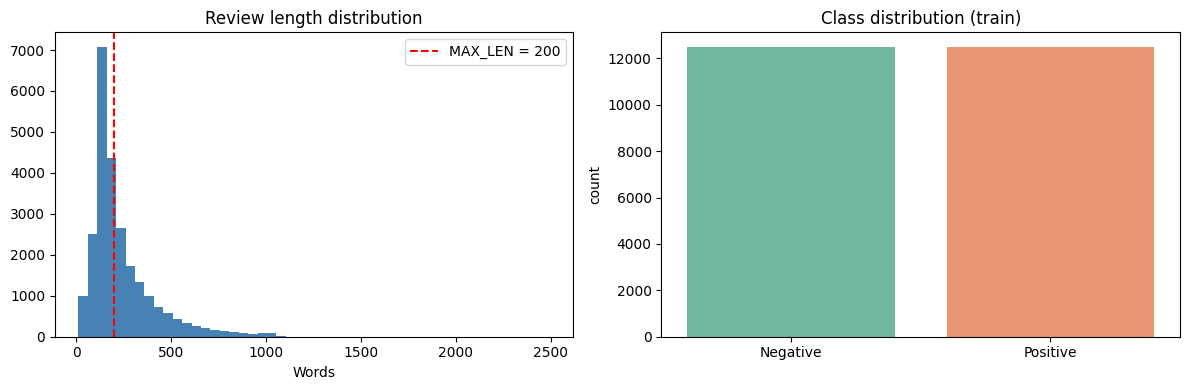

In [3]:
# Decode a few reviews back to text
word_index = imdb.get_word_index()
index_to_word = {v + 3: k for k, v in word_index.items()}
index_to_word.update({0: "<PAD>", 1: "<START>", 2: "<UNK>", 3: "<UNUSED>"})

def decode_review(seq):
    return " ".join(index_to_word.get(i, "?") for i in seq if i != 0)

for i in range(2):
    print(f"Review {i} | label = {'Positive' if y_train[i] else 'Negative'}")
    print(decode_review(x_train[i])[:400], "...\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(lengths, bins=50, color="steelblue"); axes[0].axvline(MAX_LEN, color="red", ls="--", label=f"MAX_LEN = {MAX_LEN}")
axes[0].set_title("Review length distribution"); axes[0].set_xlabel("Words"); axes[0].legend()
sns.countplot(x=y_train, ax=axes[1], palette="Set2"); axes[1].set_xticklabels(["Negative", "Positive"])
axes[1].set_title("Class distribution (train)")
plt.tight_layout(); plt.show()

## 3. Preprocessing
LSTMs in Keras need fixed-length input, so each review is **padded / truncated to `MAX_LEN` words**. We pad/truncate at the *start* (`pre`), which usually works best for LSTMs because the last words are the most recent in memory.

In [4]:
x_train_pad = pad_sequences(x_train, maxlen=MAX_LEN, padding="pre", truncating="pre")
x_test_pad  = pad_sequences(x_test,  maxlen=MAX_LEN, padding="pre", truncating="pre")
print("Padded train shape:", x_train_pad.shape, "| Padded test shape:", x_test_pad.shape)

Padded train shape: (25000, 200) | Padded test shape: (25000, 200)


## 4. Build the Model
| Layer | Purpose |
|---|---|
| `Embedding(10000, 128)` | Learns a dense 128-D vector for every word |
| `LSTM(64)` | Reads the sequence of word vectors and captures long-range context |
| `Dropout(0.5)` | Regularisation to reduce overfitting |
| `Dense(32, relu)` | Fully-connected hidden layer |
| `Dense(1, sigmoid)` | Outputs probability of the review being positive |

Loss: **binary cross-entropy**, optimiser: **Adam**.

In [5]:
EMBED_DIM = 128

model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM),
    LSTM(64, dropout=0.2),
    Dropout(0.5),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid"),
])
model.build(input_shape=(None, MAX_LEN))
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,331,521 (5.08 MB)

 Trainable params: 1,331,521 (5.08 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Train the Model
20% of the training data is held out as a validation set. **Early stopping** halts training when validation loss stops improving and restores the best weights.

In [6]:
early_stop = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True, verbose=1)

history = model.fit(
    x_train_pad, y_train,
    epochs=10, batch_size=128,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1,
)

Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.7412 - loss: 0.5006 - val_accuracy: 0.8516 - val_loss: 0.3561
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8920 - loss: 0.2724 - val_accuracy: 0.8674 - val_loss: 0.3138
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9269 - loss: 0.1979 - val_accuracy: 0.8364 - val_loss: 0.5693
Epoch 4/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9348 - loss: 0.1746 - val_accuracy: 0.8266 - val_loss: 0.5019
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.


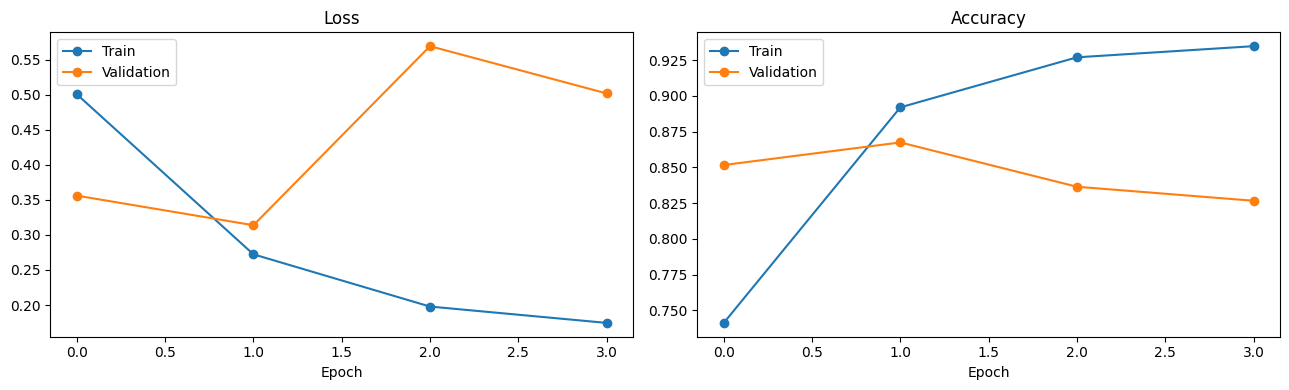

In [7]:
hist = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(hist["loss"], marker="o", label="Train"); axes[0].plot(hist["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(hist["accuracy"], marker="o", label="Train"); axes[1].plot(hist["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

## 6. Model Evaluation
Accuracy alone can be misleading, so we also report **precision, recall, F1-score, the confusion matrix and ROC-AUC** on the unseen test set.

In [8]:
test_loss, test_acc = model.evaluate(x_test_pad, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

y_prob = model.predict(x_test_pad, batch_size=256, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Score": [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
              recall_score(y_test, y_pred), f1_score(y_test, y_pred), roc_auc_score(y_test, y_prob)],
}).round(4)
metrics

Test loss: 0.3212 | Test accuracy: 0.8639


,Metric,Score
0,Accuracy,0.8639
1,Precision,0.8472
2,Recall,0.8880
3,F1-score,0.8671
4,ROC-AUC,0.9391


In [9]:
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], digits=4))

              precision    recall  f1-score   support

    Negative     0.8823    0.8398    0.8606     12500
    Positive     0.8472    0.8880    0.8671     12500

    accuracy                         0.8639     25000
   macro avg     0.8648    0.8639    0.8638     25000
weighted avg     0.8648    0.8639    0.8638     25000



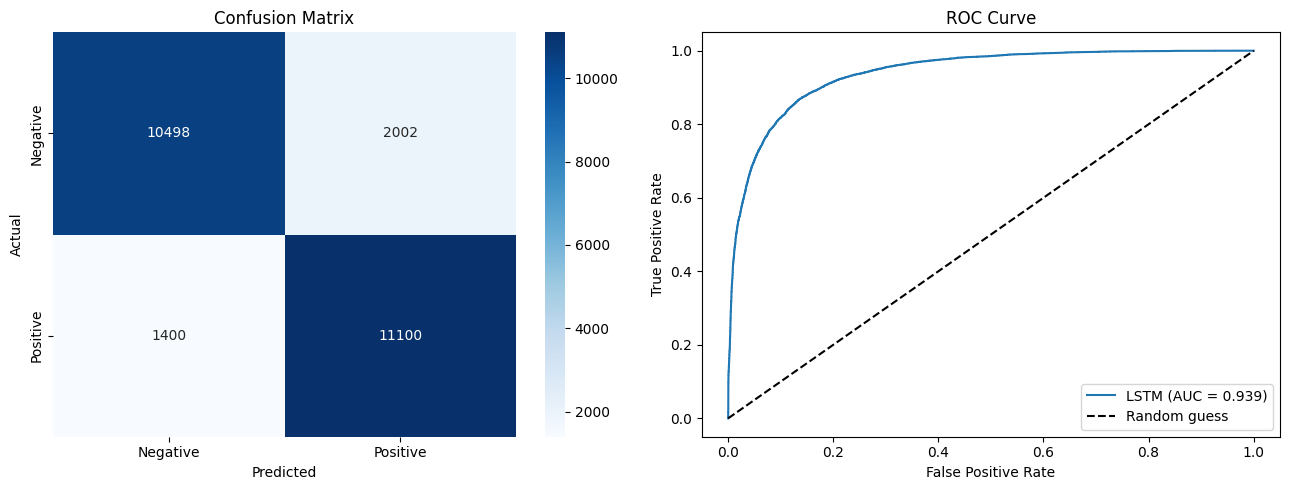

True Negatives: 10498 | False Positives: 2002 | False Negatives: 1400 | True Positives: 11100


In [10]:
cm = confusion_matrix(y_test, y_pred)
fpr, tpr, _ = roc_curve(y_test, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual"); axes[0].set_title("Confusion Matrix")

axes[1].plot(fpr, tpr, label=f"LSTM (AUC = {roc_auc_score(y_test, y_prob):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve"); axes[1].legend()
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives: {tn} | False Positives: {fp} | False Negatives: {fn} | True Positives: {tp}")

## 7. Error Analysis
Let's look at some reviews the model got wrong and how confident it was.

In [11]:
wrong_idx = np.where(y_pred != y_test)[0]
print(f"Misclassified reviews: {len(wrong_idx)} of {len(y_test)} ({len(wrong_idx)/len(y_test):.2%})\n")

rng = np.random.default_rng(SEED)
for i in rng.choice(wrong_idx, 4, replace=False):
    actual = "Positive" if y_test[i] else "Negative"
    predicted = "Positive" if y_pred[i] else "Negative"
    print(f"Actual: {actual} | Predicted: {predicted} | P(positive) = {y_prob[i]:.3f}")
    print(decode_review(x_test[i])[:350], "...\n")

Misclassified reviews: 3402 of 25000 (13.61%)

Actual: Positive | Predicted: Negative | P(positive) = 0.370
<START> i would say <UNK> of is a return to greatness but the series was never really great very good 1 was 2 3 were <UNK> and i think this 4th installment is equal to or even better than the first movie and it contains the best <UNK> <UNK> <UNK> gets lucky so he does in the role of jennifer <UNK> who thoroughly <UNK> this series as <UNK> ryan did  ...

Actual: Negative | Predicted: Positive | P(positive) = 0.828
<START> one day someone said lets <UNK> the <UNK> squad we can make it hip cool and all that <UNK> it'll make a <UNK> then they actually made it and as you are watching it you can hear your <UNK> cringe in agony as it twists and <UNK> into a <UNK> from the pure horror of it all any movie ever made has something on this id rather meet wayne <UNK> an ...

Actual: Negative | Predicted: Positive | P(positive) = 0.598
<START> does anyone remember the alternative comedy show t

## 8. Predict on New Custom Reviews

In [12]:
def encode_text(text):
    tokens = re.sub(r"[^a-z' ]", " ", text.lower()).split()
    seq = [1]  # <START>
    for w in tokens:
        idx = word_index.get(w)
        seq.append(idx + 3 if idx is not None and idx + 3 < VOCAB_SIZE else 2)  # 2 = <UNK>
    return pad_sequences([seq], maxlen=MAX_LEN, padding="pre", truncating="pre")

def predict_sentiment(text):
    p = float(model.predict(encode_text(text), verbose=0)[0][0])
    return ("Positive" if p >= 0.5 else "Negative"), p

samples = [
    "This movie was absolutely fantastic! Great acting and a wonderful story.",
    "Terrible film. The plot was boring and the acting was awful. Complete waste of time.",
    "The visuals were stunning, but the story dragged on and I nearly fell asleep.",
    "One of the best movies I have seen this year, I loved every minute of it.",
]
for s in samples:
    label, p = predict_sentiment(s)
    print(f"{label:8s} (P(positive) = {p:.3f}) -> {s}")

Positive (P(positive) = 0.962) -> This movie was absolutely fantastic! Great acting and a wonderful story.
Negative (P(positive) = 0.005) -> Terrible film. The plot was boring and the acting was awful. Complete waste of time.
Positive (P(positive) = 0.608) -> The visuals were stunning, but the story dragged on and I nearly fell asleep.
Positive (P(positive) = 0.939) -> One of the best movies I have seen this year, I loved every minute of it.


## 9. Conclusion
- An **Embedding + LSTM** network was built to classify IMDB movie reviews as positive or negative.
- The **Embedding layer** converts word indices into dense, learnable vectors that capture word meaning, and the **LSTM** models word order and context across the review, which a simple bag-of-words approach cannot do.
- The model was evaluated on 25,000 unseen test reviews using accuracy, precision, recall, F1-score, a confusion matrix and ROC-AUC. Because the classes are balanced, accuracy and F1 are consistent with each other; precision and recall show whether the model is biased towards one class.
- Typical performance for this architecture is around **85-88% accuracy** (exact values vary by run – see the results above).
- Error analysis shows that mistakes are mostly on mixed or sarcastic reviews and on long reviews truncated to `MAX_LEN` words.

